Valentina Paula Riveros Díaz
22.608.446-0


In [ ]:
import numpy as np #importo la libreria numpy para utilizarla en calculos mas adeltante
import matplotlib.pyplot as plt#importo la liberia matplotlib.pyplot para generar graficos mas adelante

In [ ]:
rng = np.random.default_rng(seed = 11223)#defino la semilla de mi codigo

Primer Item

In [ ]:
#Genero el arreglo temporal que cubre un intervalo de diez años compuesto por 500 mediciones equidistantes
arreglo_t = np.linspace(0, 10, 500)
# Genero un arreglo de tamaño 500 lleno de 1.
flujo = np.ones(500)
#Simulo el transito entre t =4.5 y t=5 años, y utilizo una mascara para encontrar el tiempo en el intervalo
# Usamos una máscara para encontrar los tiempos dentro del primer intervalo
mascara_transito1 = (arreglo_t >= 4.5) & (arreglo_t <= 5.0)
flujo[mascara_transito1] -= 0.02
#Simulo el transito entre t =7.0 y t=7.4 años, y utilizo una mascara para encontrar el tiempo en el intervalo
# Usamos una máscara para encontrar los tiempos dentro del segundo intervalo
mascara_transito2 = (arreglo_t >= 7.0) & (arreglo_t <= 7.4)
flujo[mascara_transito2] -= 0.015
# Disminuyo el flujo en una escala de 0.02 y tamaño 500
flujo_disminuido = rng.normal(loc=0.0, scale=0.02, size=500)
flujo_observado= flujo + flujo_disminuido

(a) Cree una función que, dado un arreglo de tiempos y un arreglo de flujo, genere
una figura de la curva de luz completa. La figura debe cumplir con las siguientes
características:

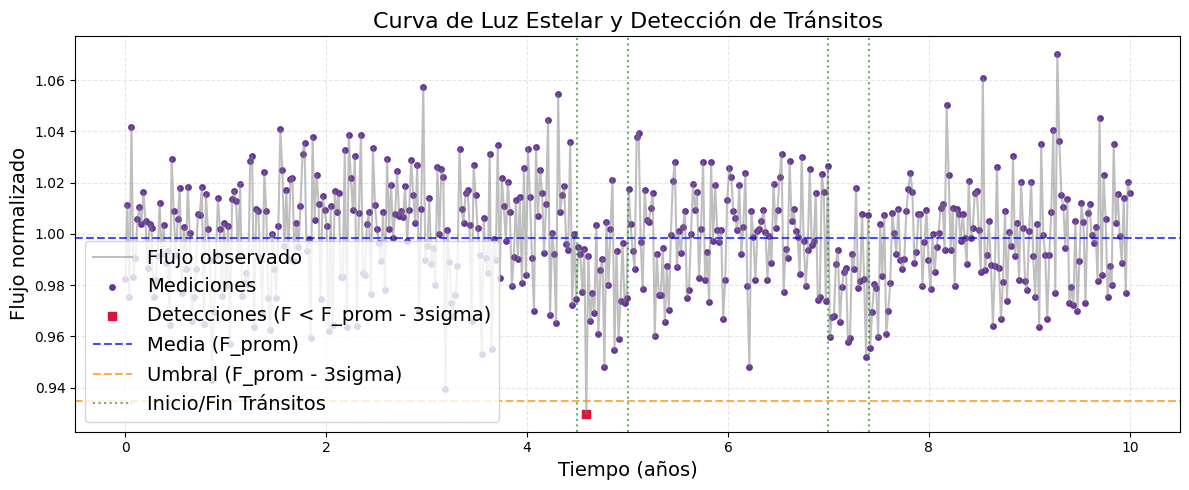

In [ ]:
#Escribo la funcion graficar_curva con los parametros de tiempo y flujo.
def graficar_curva(tiempos, flujo):
    flujo_prom = np.mean(flujo)#Calculo el promedio ocupando la funcion np.mean de Numpy
    flujo_std = np.std(flujo)#Calculo la desviación estándar ocupando la funcin on np.std de Numpy

    umbral = flujo_prom - 3 * flujo_std #ocupo la formula entregada en las instrucciones
    mascara_3sigma = flujo < umbral
    #Selecciono  los  puntos que cumplan F < F_prom - 3*sigma
    puntos_filtrados = flujo[mascara_3sigma]
    tiempos_filtrados = tiempos[mascara_3sigma]
    #Ocupo una mascara para identificar los puntos que cumplan con la condicion inicial

    plt.figure(figsize=(12, 5))

    # Muestro todos los puntos de la curva de luz
    plt.plot(tiempos, flujo, color='gray', alpha=0.5, linestyle='-', label='Flujo observado')
    plt.scatter(tiempos, flujo, color='rebeccapurple', s=15, label='Mediciones')

    # Resalto con color y marcador diferente los puntos que cumplen la condición
    plt.scatter(tiempos_filtrados, puntos_filtrados,
                color='crimson', marker='s', s=30, label=r'Detecciones (F < F_prom - 3sigma)')

    # Escribo las líneas horizontales con valor medio y umbral de detección
    plt.axhline(flujo_prom, color='blue', linestyle='--', alpha=0.7, label='Media (F_prom)')
    plt.axhline(umbral, color='darkorange', linestyle='--', alpha=0.7, label='Umbral (F_prom - 3sigma)')

    # Escribo las líneas verticales que marquen el inicio y fin de cada tránsito simulado
    plt.axvline(4.5, color='green', linestyle=':', alpha=0.6, label='Inicio/Fin Tránsitos')
    plt.axvline(5.0, color='green', linestyle=':', alpha=0.6)
    plt.axvline(7.0, color='green', linestyle=':', alpha=0.6)
    plt.axvline(7.4, color='green', linestyle=':', alpha=0.6)

    # escribo las etiquetas en ambos ejes, título y leyenda con tamaño de fuente 14 como indican las instrucciones
    plt.xlabel('Tiempo (años)', fontsize=14)
    plt.ylabel('Flujo normalizado', fontsize=14)
    plt.title('Curva de Luz Estelar y Detección de Tránsitos', fontsize=16)
    plt.legend(fontsize=14, loc='lower left')

    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

# Ejecuto mi funcion
graficar_curva(arreglo_t, flujo_observado)

In [ ]:
# Defino la semilla de mi código y escribo las variables iniciales
rng = np.random.default_rng(seed=1122)

I0 = 100
sigma = 0.5
Nestrellas = 5

# Escribo las posiciones aleatorias de las 5 estrellas entre -5 y 5 como se indica
x0 = rng.uniform(-5, 5, Nestrellas)
y0 = rng.uniform(-5, 5, Nestrellas)

# Creo una malla de coordenadas espaciales (x e y) para la imagen
N_pixeles = 300
x = np.linspace(-5, 5, N_pixeles)
y = np.linspace(-5, 5, N_pixeles)
X, Y = np.meshgrid(x, y)

# Inicio la matriz de la imagen rellenando con ceros
imagen = np.zeros((N_pixeles, N_pixeles))

# Sumo la contribución gaussiana de cada estrella
for i in range(Nestrellas):
    intensidad = I0 * np.exp(- ((X - x0[i])**2 + (Y - y0[i])**2) / (2 * sigma**2))
    imagen += intensidad

# Genero la imagen
plt.figure(figsize=(8, 6))
plt.imshow(imagen, origin='lower', extent=[-5, 5, -5, 5], cmap='inferno')

# Escribo las etiquetas con tamaño de fuente 14
plt.colorbar(label='Intensidad de luz')
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.title('Imagen Astronómica de 5 Estrellas', fontsize=14)
plt.show()